### Exploratory Data Analysis (EDA):

#### 1.	Load the dataset using Python's pandas library.

In [56]:
import pandas as pd

In [57]:
data=pd.read_csv("diabetes.csv")
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


#### 2.	Check for missing values.

In [3]:
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

#### 3.	Explore data distributions using histograms and box plots.

In [4]:
data.columns

Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'],
      dtype='object')

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

#### Histplot

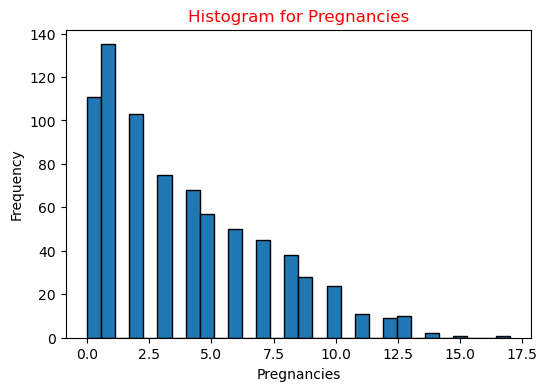

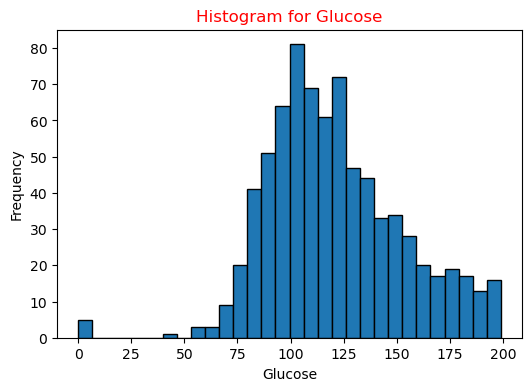

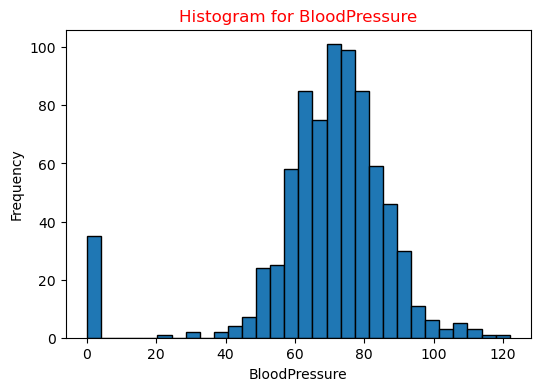

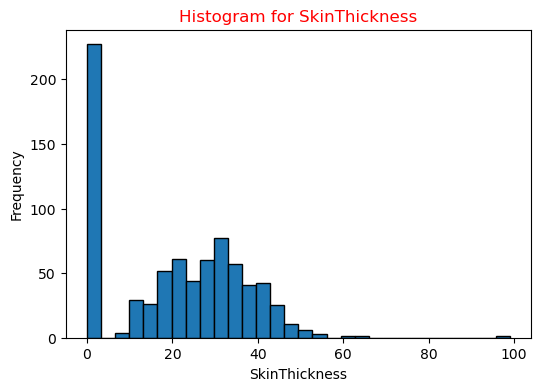

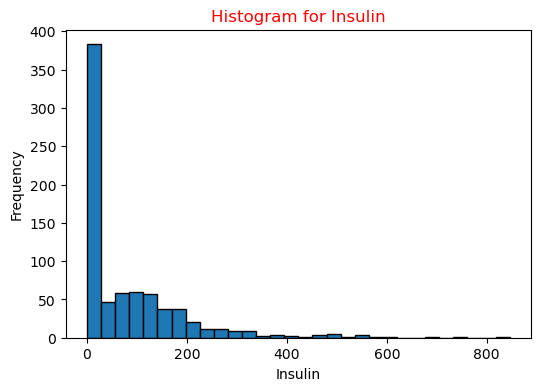

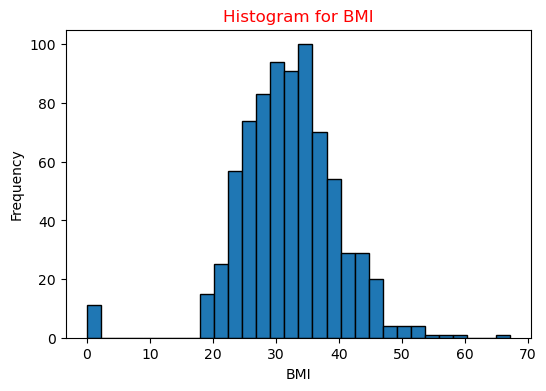

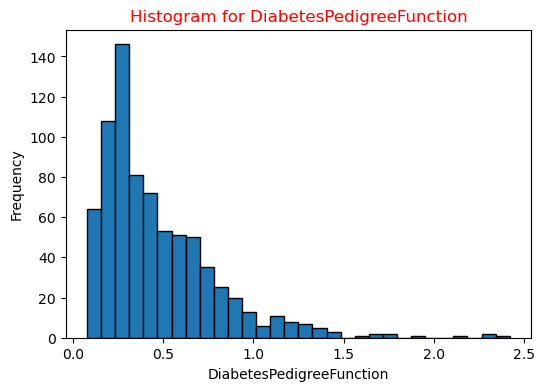

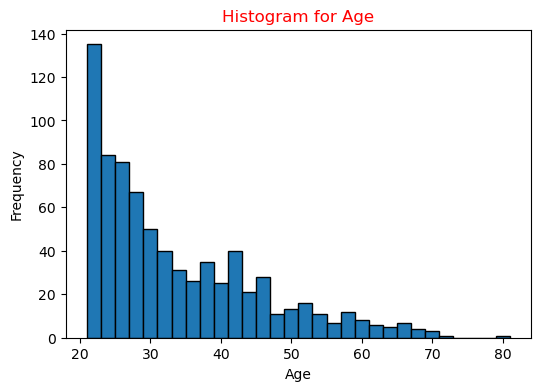

In [60]:
col=["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin",
       "BMI","DiabetesPedigreeFunction","Age"]
for i in col:
    plt.figure(figsize=(6,4))
    plt.hist(data[i],bins=30,edgecolor="k")
    plt.title(f"Histogram for {i}",color="red")
    plt.xlabel(i)
    plt.ylabel("Frequency")
    plt.show()

#### A histogram shows the distribution of each numerical feature.

#### BoxPlot

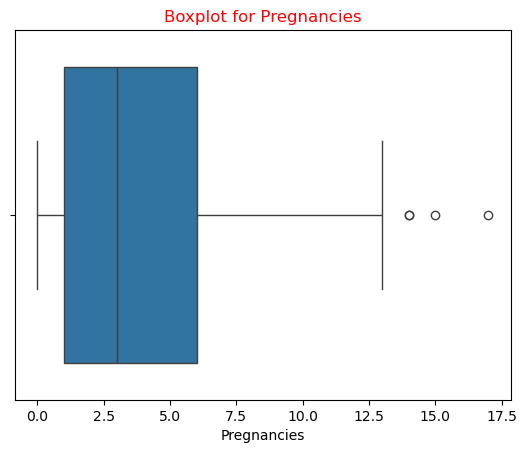

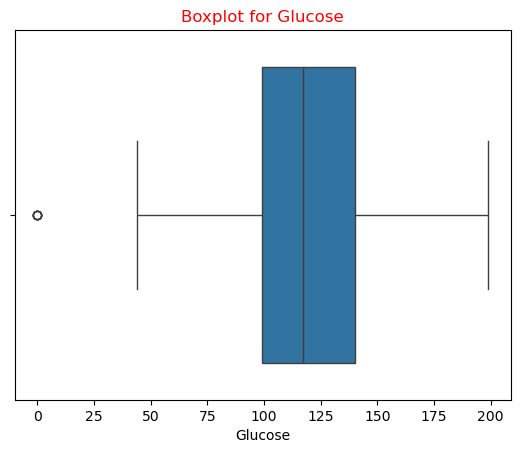

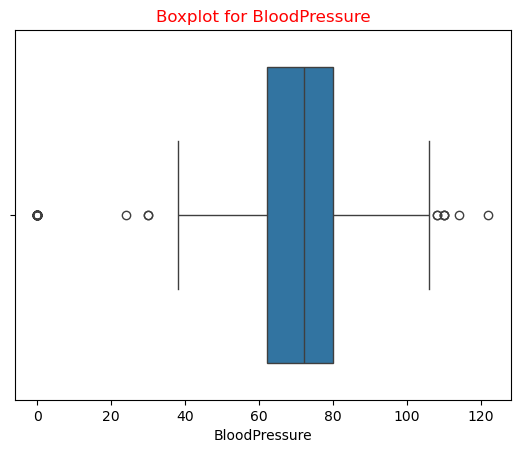

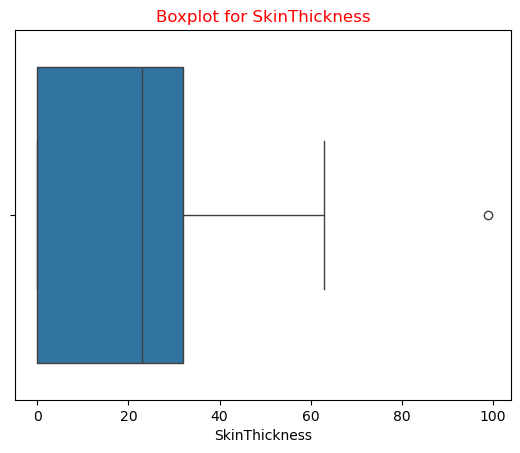

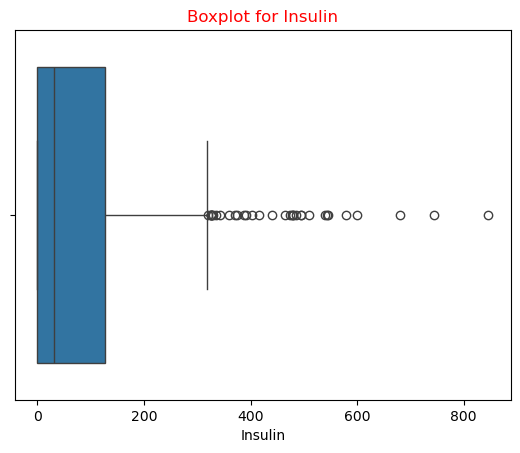

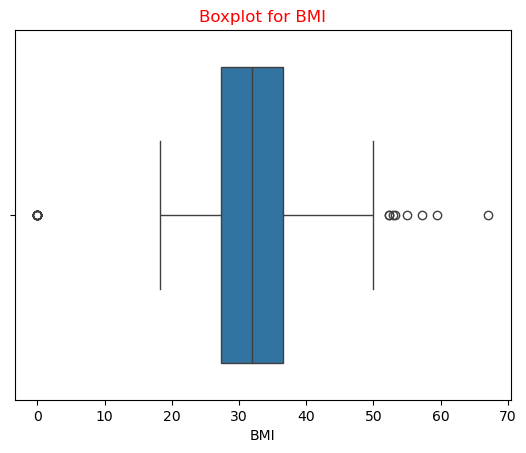

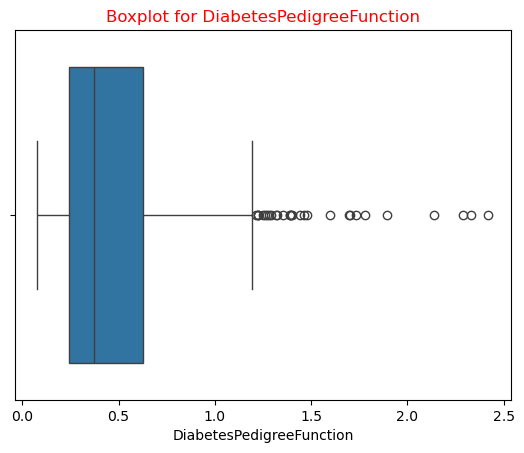

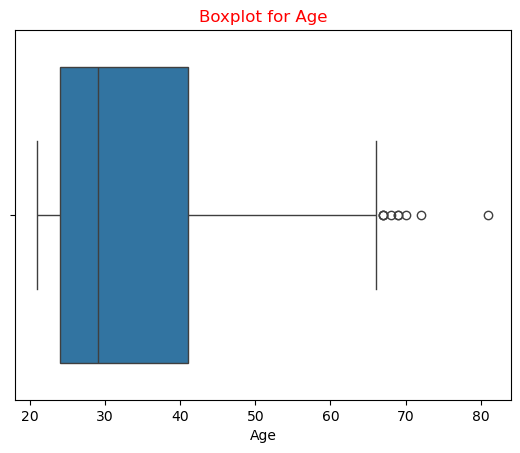

In [7]:
col=["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin",
       "BMI","DiabetesPedigreeFunction","Age"]
for i in col:
    sns.boxplot(x=data[i])
    plt.title(f"Boxplot for {i}",color="red")
    plt.xlabel(i)
    plt.show()

#### Boxplots help identify possible outliers using the quartiles and IQR

#### 4.	Visualize relationships between features and outcome using scatter plots and bar plots.

#### Scatterplot

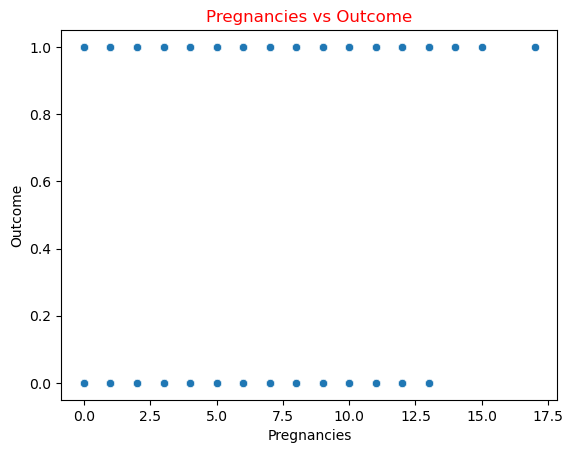

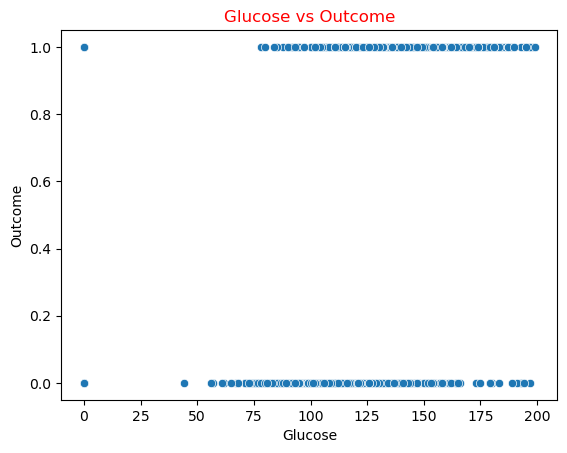

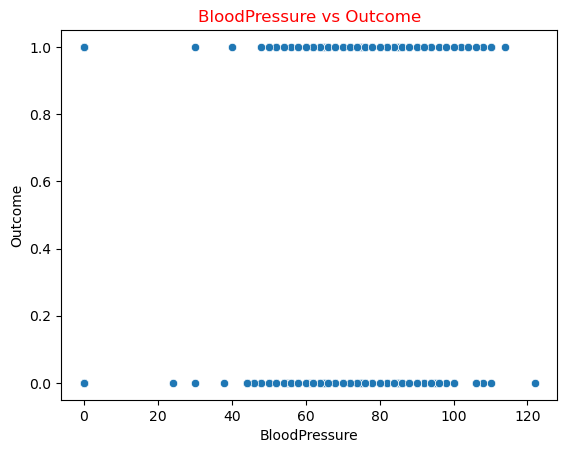

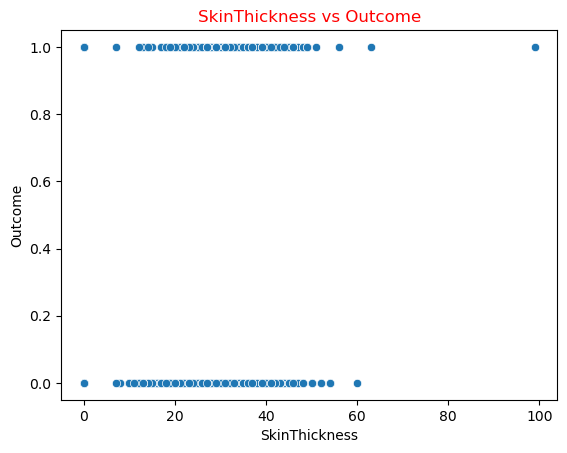

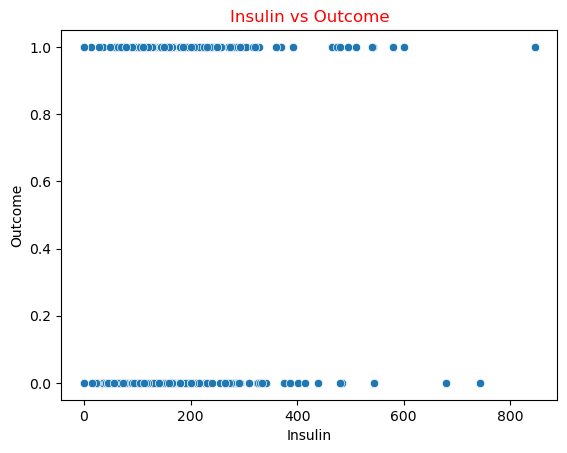

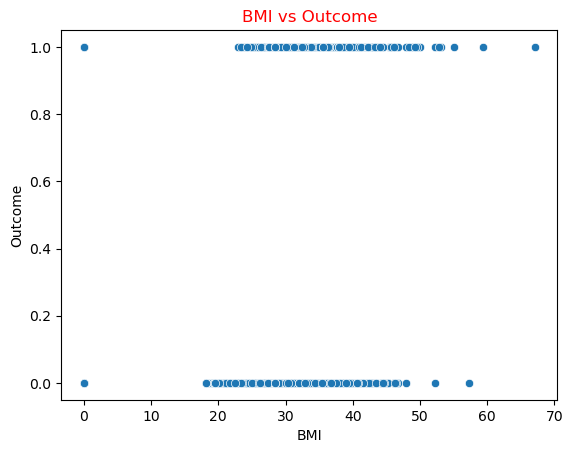

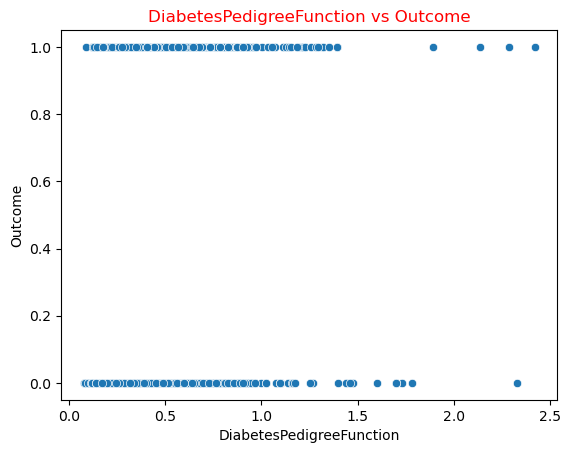

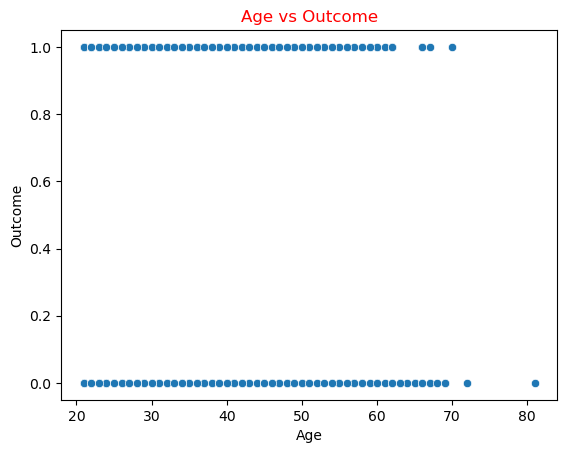

In [8]:
col=["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin",
       "BMI","DiabetesPedigreeFunction","Age"]
for i in col:
    sns.scatterplot(data,x=i,y="Outcome")
    plt.title(f"{i} vs Outcome",color="red")
    plt.xlabel(i)
    plt.ylabel("Outcome")
    plt.show()

#### BarPlot

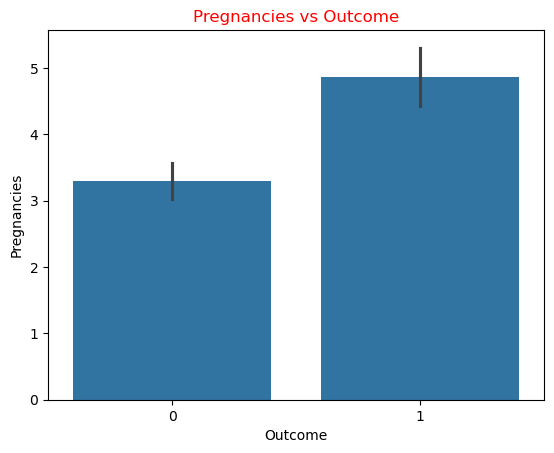

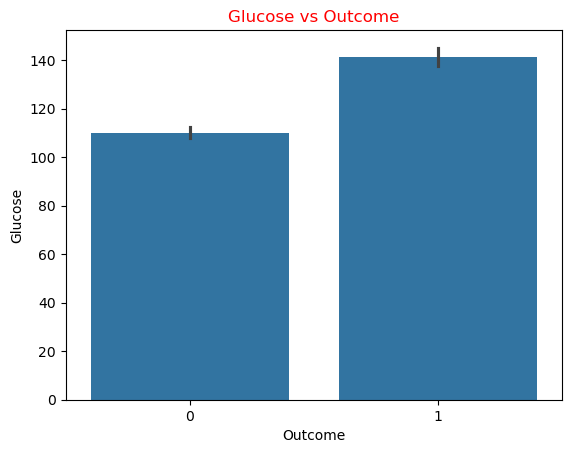

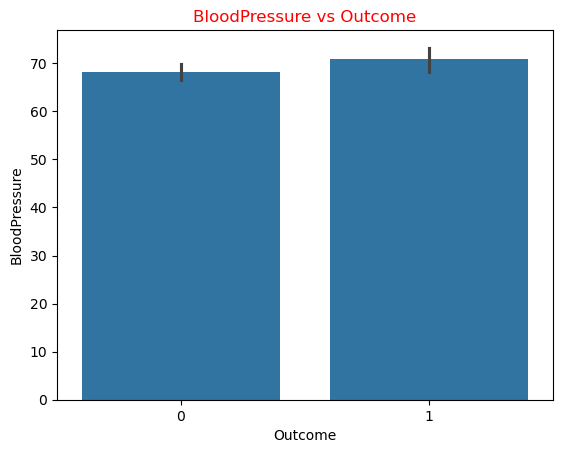

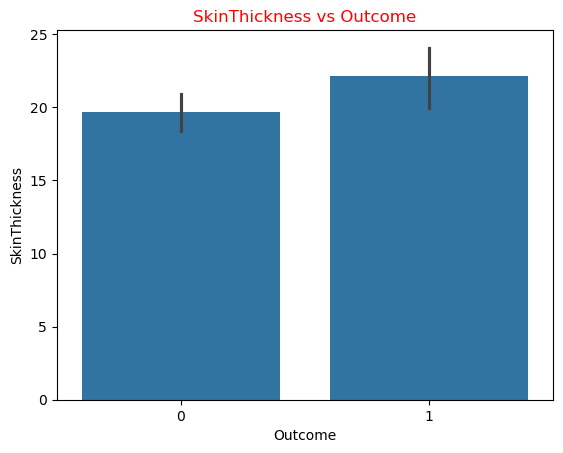

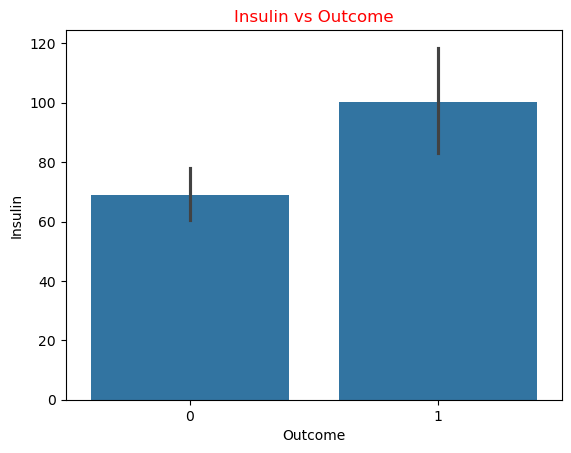

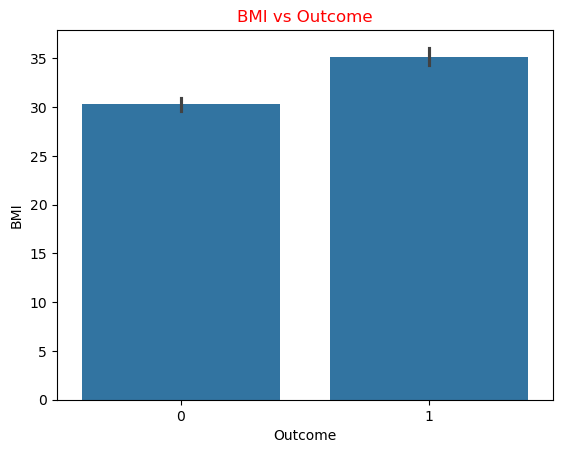

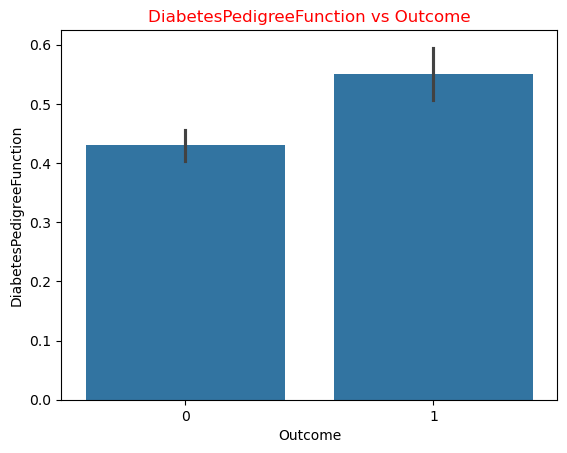

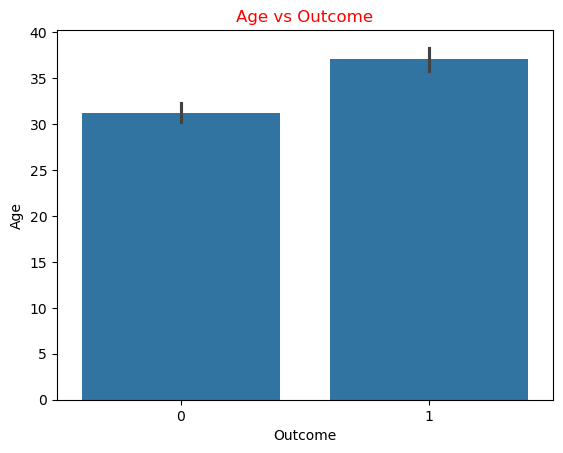

In [9]:
col=["Pregnancies","Glucose","BloodPressure","SkinThickness","Insulin",
       "BMI","DiabetesPedigreeFunction","Age"]
for i in col:
    sns.barplot(data,x="Outcome",y=i)
    plt.title(f"{i} vs Outcome",color="red")
    plt.xlabel("Outcome")
    plt.ylabel(i)
    plt.show()

In [10]:
corr=data.corr()
corr

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.129459,0.141282,-0.081672,-0.073535,0.017683,-0.033523,0.544341,0.221898
Glucose,0.129459,1.000000,0.152590,0.057328,0.331357,0.221071,0.137337,0.263514,0.466581
BloodPressure,0.141282,0.152590,1.000000,0.207371,0.088933,0.281805,0.041265,0.239528,0.065068
SkinThickness,-0.081672,0.057328,0.207371,1.000000,0.436783,0.392573,0.183928,-0.113970,0.074752
Insulin,-0.073535,0.331357,0.088933,0.436783,1.000000,0.197859,0.185071,-0.042163,0.130548
BMI,0.017683,0.221071,0.281805,0.392573,0.197859,1.000000,0.140647,0.036242,0.292695
DiabetesPedigreeFunction,-0.033523,0.137337,0.041265,0.183928,0.185071,0.140647,1.000000,0.033561,0.173844
Age,0.544341,0.263514,0.239528,-0.113970,-0.042163,0.036242,0.033561,1.000000,0.238356
Outcome,0.221898,0.466581,0.065068,0.074752,0.130548,0.292695,0.173844,0.238356,1.000000


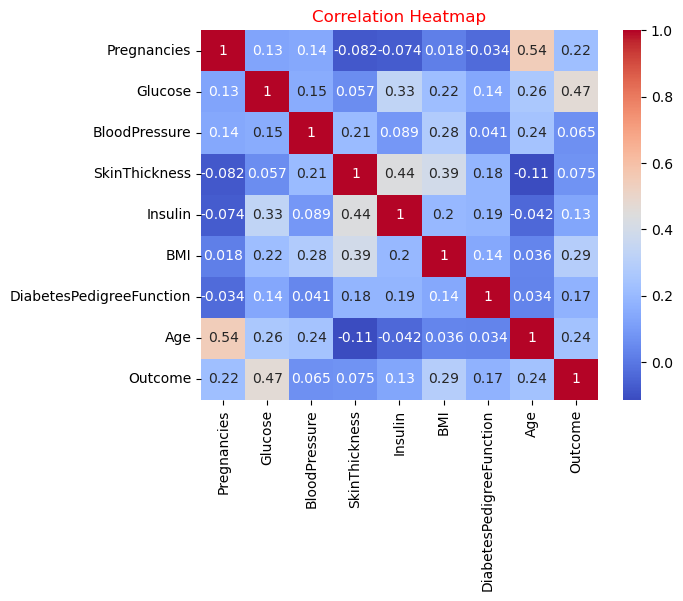

In [11]:
sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.title("Correlation Heatmap",color="red")
plt.show()

### Data Preprocessing:

#### 1.	Impute missing values.

In [12]:
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [13]:
import numpy as np
missing_col=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
data[missing_col]=data[missing_col].replace(0,np.nan)
data.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

#### Although isnull().sum() initially showed no missing values, some medicalfeatures contained zero values that are not realistic measurements.Therefore, zero values in Glucose, BloodPressure, SkinThickness, Insulin,and BMI were treated as missing values and replaced with the median.

In [14]:
for i in missing_col:
    data[i]=data[i].fillna(data[i].median())

In [15]:
data.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

#### 2.	Encode categorical variables using one-hot encoding or label encoding. 

In [16]:
data.select_dtypes(include="object").columns

Index([], dtype='object')

#### There are no categorical/object columns in the dataset.Therefore, label encoding or one-hot encoding is not required.

In [17]:
data.duplicated().sum()

np.int64(0)

In [18]:
data["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

#### Visualization

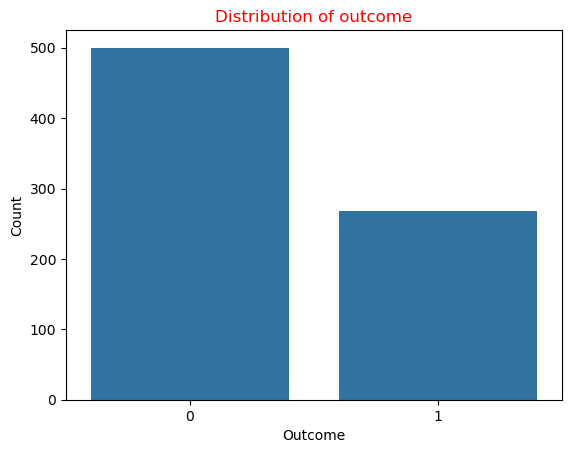

In [19]:
sns.countplot(data,x="Outcome")
plt.title("Distribution of outcome",color="red")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.show()

### Building Predictive Models:

#### 1.	Split the preprocessed dataset into training and testing sets.

In [20]:
x=data.drop("Outcome",axis=1)
y=data["Outcome"]

In [21]:
from sklearn.model_selection import train_test_split 
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((614, 8), (154, 8), (614,), (154,))

#### 2.	Choose appropriate evaluation metrics (e.g., accuracy, precision, recall, F1-score) for model evaluation.

In [22]:
from sklearn.metrics import accuracy_score,precision_score,f1_score,recall_score,confusion_matrix,classification_report

In [23]:
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

In [24]:
lgbm_model=LGBMClassifier(random_state=42,verbosity=-1)
xgb_model=XGBClassifier(random_state=42,eval_metric="logloss")

In [25]:
lgbm_model.fit(x_train,y_train)

,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [26]:
xgb_model.fit(x_train,y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [27]:
lgbm_pred=lgbm_model.predict(x_test)
lgbm_pred

array([1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0])

In [28]:
xgb_pred=xgb_model.predict(x_test)
xgb_pred

array([1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 0, 1,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0,
       0, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0])

In [29]:
print("LIGHTGBM PERFORMANCE")
print("--------------------")
print("Accuracy_score :",accuracy_score(y_test,lgbm_pred))
print("Precision_score:",precision_score(y_test,lgbm_pred))
print("Recall_score   :",recall_score(y_test,lgbm_pred))
print("F1_score       :",f1_score(y_test,lgbm_pred))

LIGHTGBM PERFORMANCE
--------------------
Accuracy_score : 0.7662337662337663
Precision_score: 0.68
Recall_score   : 0.6296296296296297
F1_score       : 0.6538461538461539


In [30]:
print("XGBOOST PERFORMANCE")
print("-------------------")
print("Accuracy_score  :",accuracy_score(y_test,xgb_pred))
print("Precision_score :",precision_score(y_test,xgb_pred))
print("Recall_score    :",recall_score(y_test,xgb_pred))
print("F1_score        :",f1_score(y_test,xgb_pred))

XGBOOST PERFORMANCE
-------------------
Accuracy_score  : 0.7727272727272727
Precision_score : 0.7021276595744681
Recall_score    : 0.6111111111111112
F1_score        : 0.6534653465346535


In [31]:
print("LightGBM Classification Report")
print(classification_report(y_test,lgbm_pred))

LightGBM Classification Report
              precision    recall  f1-score   support

           0       0.81      0.84      0.82       100
           1       0.68      0.63      0.65        54

    accuracy                           0.77       154
   macro avg       0.74      0.73      0.74       154
weighted avg       0.76      0.77      0.76       154



In [32]:
print("XGBoost Classification Report")
print(classification_report(y_test,xgb_pred))

XGBoost Classification Report
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



#### Confusion Matrix

In [33]:
cm_lgbm=confusion_matrix(y_test,lgbm_pred)
cm_lgbm

array([[84, 16],
       [20, 34]])

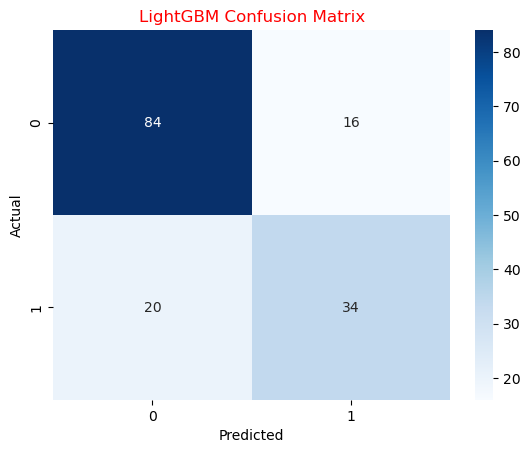

In [59]:
sns.heatmap(cm_lgbm,annot=True,fmt="d",cmap="Blues")
plt.title("LightGBM Confusion Matrix",color="red")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [35]:
cm_xgb=confusion_matrix(y_test,xgb_pred)
cm_xgb

array([[86, 14],
       [21, 33]])

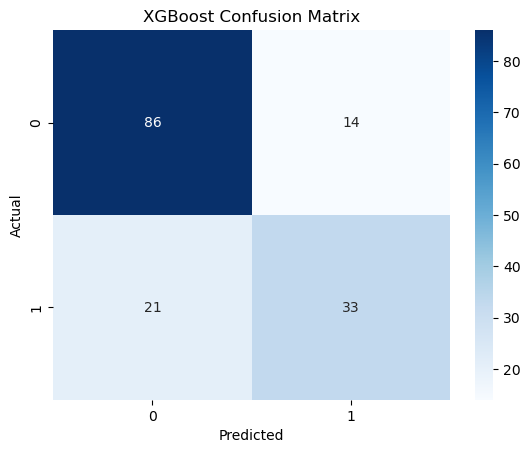

In [36]:
sns.heatmap(cm_xgb,annot=True,fmt="d",cmap="Blues")
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

#### Cross Validation

In [37]:
from sklearn.model_selection import cross_val_score

In [38]:
lgbm_cv=cross_val_score(lgbm_model,x,y,cv=5,scoring="accuracy")
print("LightGBM CV Scored:",lgbm_cv)
print("LightGBM Mean CV Accuracy:",lgbm_cv.mean())

LightGBM CV Scored: [0.74675325 0.74025974 0.74675325 0.79084967 0.73856209]
LightGBM Mean CV Accuracy: 0.7526355996944232


In [39]:
xgb_cv=cross_val_score(xgb_model,x,y,cv=5,scoring="accuracy")
print("XGBoost CV Scores:",xgb_cv)
print("XGBoost Mean CV Accuracy:",xgb_cv.mean())

XGBoost CV Scores: [0.72727273 0.71428571 0.74675325 0.78431373 0.77124183]
XGBoost Mean CV Accuracy: 0.7487734487734488


In [40]:
print("LightGBM Mean CV Accuracy:",lgbm_cv.mean())
print("XGBoost Mean CV Accuracy:",xgb_cv.mean())

LightGBM Mean CV Accuracy: 0.7526355996944232
XGBoost Mean CV Accuracy: 0.7487734487734488


#### Hyperparameter Tuning

In [41]:
from sklearn.model_selection import GridSearchCV
lgbm_param={"n_estimators":[50,100,200],"learning_rate":[0.01,0.05,0.1],"max_depth":[-1,3,5]}
lgbm_grid=GridSearchCV(LGBMClassifier(random_state=42),param_grid=lgbm_param,cv=5,scoring="accuracy",n_jobs=-1)
lgbm_grid.fit(x_train,y_train)

,estimator,LGBMClassifie...ndom_state=42)
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [-1, 3, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,boosting_type,'gbdt'


In [42]:
print("Best LightGBM Parameters:")
print(lgbm_grid.best_params_)

Best LightGBM Parameters:
{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}


In [43]:
print("Best LightGBM CV Score:")
print(lgbm_grid.best_score_)

Best LightGBM CV Score:
0.7703985072637611


In [44]:
xgb_params={"n_estimators":[50,100,200],"learning_rate":[0.01,0.05,0.1],"max_depth":[3,5,7]}
xgb_grid=GridSearchCV(XGBClassifier(random_state=42,eval_metric="logloss"),param_grid=xgb_params,cv=5,scoring="accuracy",n_jobs=-1)
xgb_grid.fit(x_train,y_train)

,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'n_estimators': [50, 100, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [45]:
print("Best XGBoost Parameters:")
print(xgb_grid.best_params_)

Best XGBoost Parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 50}


In [46]:
print("Best XGBoost CV Score:")
print(xgb_grid.best_score_)

Best XGBoost CV Score:
0.7622950819672132


In [47]:
best_lgbm=lgbm_grid.best_estimator_
best_xgb=xgb_grid.best_estimator_

In [48]:
lgbm_tuned_pred=best_lgbm.predict(x_test)
xgb_tuned_pred=best_xgb.predict(x_test)

#### Evaluate tuned models

In [49]:
print("Tuned LightGBM")
print("Accuracy :",accuracy_score(y_test,lgbm_tuned_pred))
print("Precision:",precision_score(y_test,lgbm_tuned_pred))
print("Recall   :",recall_score(y_test,lgbm_tuned_pred))
print("F1 Score :",f1_score(y_test,lgbm_tuned_pred))

Tuned LightGBM
Accuracy : 0.7597402597402597
Precision: 0.6888888888888889
Recall   : 0.5740740740740741
F1 Score : 0.6262626262626263


In [50]:
print("Tuned XGBoost")
print("Accuracy :",accuracy_score(y_test,xgb_tuned_pred))
print("Precision:", precision_score(y_test,xgb_tuned_pred))
print("Recall   :", recall_score(y_test,xgb_tuned_pred))
print("F1 Score :", f1_score(y_test,xgb_tuned_pred))

Tuned XGBoost
Accuracy : 0.7272727272727273
Precision: 0.6363636363636364
Recall   : 0.5185185185185185
F1 Score : 0.5714285714285714


In [51]:
results = pd.DataFrame({"Model":["LightGBM", "XGBoost"],
                        "Accuracy":[accuracy_score(y_test,lgbm_tuned_pred),accuracy_score(y_test, xgb_tuned_pred)],
                        "Precision":[precision_score(y_test,lgbm_tuned_pred),precision_score(y_test,xgb_tuned_pred)],
                        "Recall":[recall_score(y_test,lgbm_tuned_pred),recall_score(y_test,xgb_tuned_pred)],
                        "F1 Score":[f1_score(y_test,lgbm_tuned_pred),f1_score(y_test,xgb_tuned_pred)]})
results

,Model,Accuracy,Precision,Recall,F1 Score
0,LightGBM,0.759740,0.688889,0.574074,0.626263
1,XGBoost,0.727273,0.636364,0.518519,0.571429


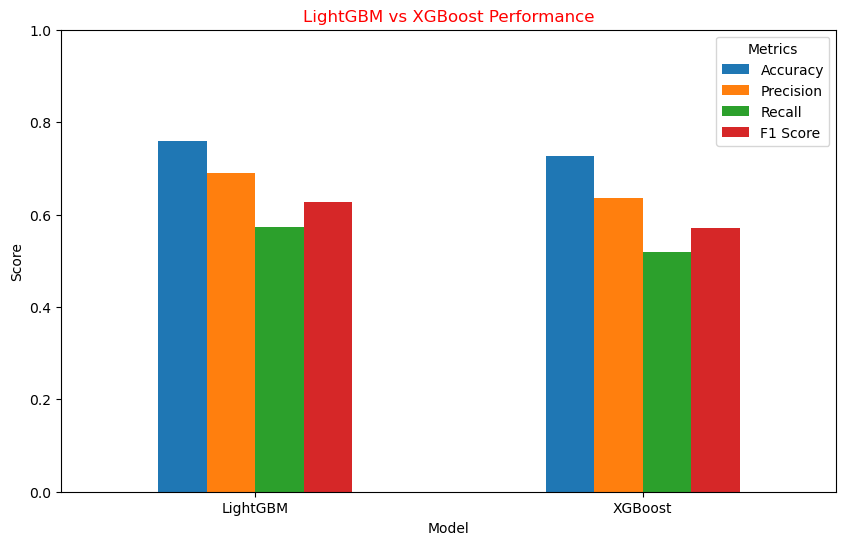

In [52]:
results_plot=results.set_index("Model")
results_plot.plot(kind="bar",figsize=(10,6))
plt.title("LightGBM vs XGBoost Performance",color="red")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.show()

#### Feature importance

In [53]:
lgbm_importance=pd.Series(best_lgbm.feature_importances_,index=x.columns).sort_values(ascending=False)
lgbm_importance

Glucose                     72
BMI                         63
DiabetesPedigreeFunction    37
Age                         37
Insulin                     25
SkinThickness               23
Pregnancies                 19
BloodPressure               10
dtype: int32

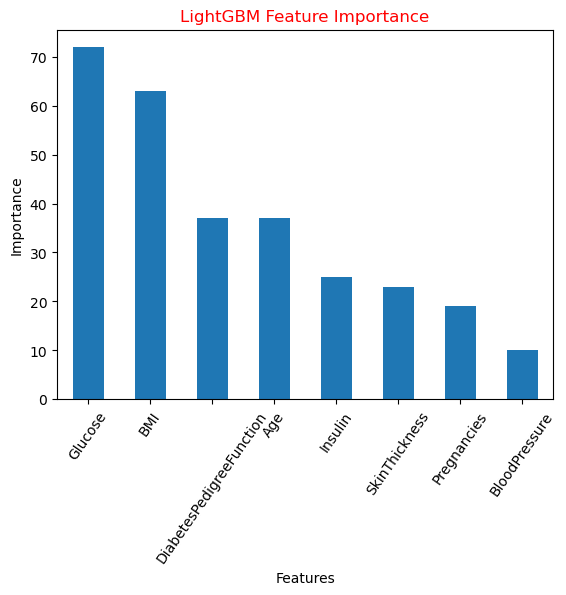

In [54]:
lgbm_importance.plot(kind="bar")
plt.title("LightGBM Feature Importance",color="red")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=55)
plt.show()

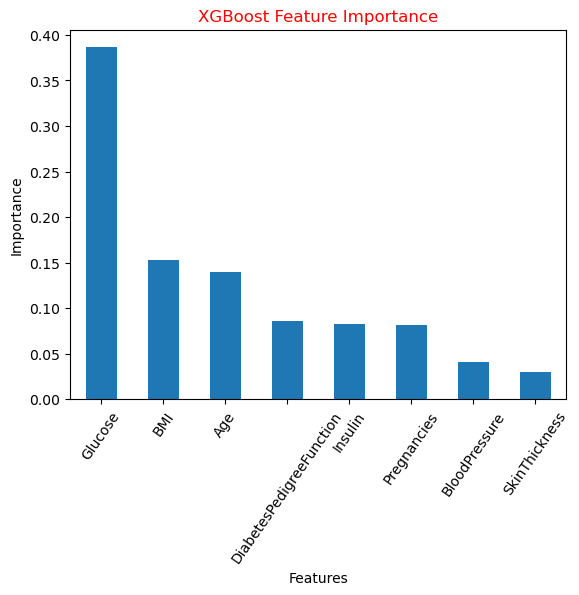

In [55]:
xgb_importance = pd.Series(best_xgb.feature_importances_,index=x.columns).sort_values(ascending=False)
xgb_importance.plot(kind="bar")
plt.title("XGBoost Feature Importance",color="red")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=55)
plt.show()

####  Comparative Analysis and Conclusion

In this assignment, LightGBM and XGBoost models were used to predict diabetes. Before building the models, the dataset was analyzed and preprocessed by handling invalid zero values and checking the data properly.

The LightGBM model achieved around 76.62% accuracy, while XGBoost achieved around 77.27% accuracy. So, XGBoost performed slightly better than LightGBM based on the initial accuracy. Both models also gave similar results for precision, recall, and F1-score.

Cross-validation and GridSearchCV were used to check and tune the performance of both models. After tuning, LightGBM achieved around 75.97% accuracy and XGBoost achieved around 72.73% accuracy. In this case, tuning did not improve the test accuracy compared to the original models.

From the feature importance results, Glucose and BMI were found to be important features for predicting diabetes.

Overall, both LightGBM and XGBoost performed well on the diabetes dataset. XGBoost gave slightly better accuracy in the original model, while LightGBM also showed good and consistent performance. Therefore, both models can be useful for classification, depending on the required performance metrics.
